# how the debate names its wars

counting topics shows what a speech is about, not which side it takes. "Ukraine" appears in Lavrov's speech and in Zelenskyy's. this notebook reads how each speech describes the two wars of the decade, and asks five questions:

1. how did each country describe the war in Ukraine in 2026?
2. how has that wording changed since 2022, and who changed it?
3. how does each country describe Gaza?
4. do the countries that condemn one war condemn the other?
5. do the words match the votes?

**how the wording is read.** a fixed set of rules in [`analysis/wording.py`](https://github.com/jeremychia/unga-speeches/blob/main/src/unga_speeches/analysis/wording.py) gives each speech its strongest framing, and keeps the sentence that shows it, so every label can be checked. for Ukraine, blame means a sentence where Russia acts ("Russia has been waging a cruel war") or the war is called aggression or an invasion; wording that puts both countries on the same footing ("the war between Russia and Ukraine") is neutral. for Gaza, the strongest framing is "genocide", then criticism of Israel's conduct, such as strikes, starvation or settlements; naming Hamas or the hostages is recorded separately, since a speech can do both.

**how well it reads.** the labels were checked against readers who never saw the rules: separate AI models, not people, each labelling speeches from the extracted sentences alone. the rules were corrected with three such checks, the last a reading of every 2026 speech, and then measured on a fresh sample of 80 speeches from 2022–2025 that no check had used. on that sample the Ukraine labels are almost always right, the Gaza genocide labels are reliable, and criticism of Israel is undercounted: the rules catch about 6 in 10 critical speeches, missing criticism that never names Israel. the scores are at the end of this notebook, and `make wording` rebuilds every label from [`analysis/wording.py`](https://github.com/jeremychia/unga-speeches/blob/main/src/unga_speeches/analysis/wording.py).

**the texts change kind.** 2022–2024 are the UN's official records, 2025 is a transcript of the interpreters, and 2026 is mostly the text each delegation filed. year-to-year changes are large next to that, but small ones should be read with care.

In [1]:
import pathlib
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy import stats

from unga_speeches.analysis import wording
from unga_speeches.analysis.charts import (BLUE, BLUE_INK, HONEY, INK, INK_2, MUTED, NOT_RAISED, RAMP, ROSE, ROSE_INK, SQUARE, SURFACE,
                                           finalize, legend, show, style, world, world_map)

style()
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
ref = pd.read_csv(ROOT / "reference/delegations.csv")
REGION = dict(zip(ref.iso3, ref.m49_region))
STATES = set(ref.iso3.dropna())

# every speech since the war in Ukraine began, labelled by the rules in analysis/wording.py (the same table `make wording` writes)
classified = wording.classify()
ukr = classified.rename(columns={"ukraine": "cls", "ukraine_evidence": "evidence"})
gz = classified[classified.year >= wording.FIRST_YEAR["gaza"]].rename(columns={"gaza": "cls", "gaza_evidence": "evidence"}).reset_index(drop=True)
texts = pd.read_parquet(ROOT / "data/output/speeches.parquet", columns=["year", "iso3", "delegation", "speaker_name", "speaker_title", "english_text_clean"])
texts = texts[(texts.year >= wording.FIRST_YEAR["ukraine"]) & (texts.english_text_clean.str.split().str.len() >= wording.MIN_WORDS)]
votes = pd.read_csv(ROOT / "reference/ukraine_votes.csv").pivot(index="iso3", columns="resolution", values="vote")

BLAMES, NO_BLAME, RUSSIAS, SILENT = wording.UKRAINE_CLASSES
GENOCIDE, CONDUCT, NO_CRITICISM, NO_GAZA = wording.GAZA_CLASSES
# one colour per framing, the same in every chart: blue for blame, light blue for wording that blames no one, rose for Russia's framing
UK = {BLAMES: BLUE_INK, NO_BLAME: "#8fcdf0", RUSSIAS: ROSE, SILENT: NOT_RAISED}
GZ = dict(zip(wording.GAZA_CLASSES, [ROSE_INK, "#eaa0bb", "#8fcdf0", NOT_RAISED]))  # light blue is wording that blames no one, in both wars
YEARS = [2022, 2023, 2024, 2025, 2026]
print(pd.crosstab(ukr.cls, ukr.year).loc[list(UK)])
print(pd.crosstab(gz.cls, gz.year).loc[list(GZ)])


def say(df, n=4, prefer=("USA", "CHN", "IND", "BRA", "FRA", "GBR", "DEU", "TUR", "ZAF", "JPN", "SAU", "IDN", "NGA", "MEX", "RUS", "ISR", "PSE"), col="evidence"):
    """print up to n of the sentences behind a group of speeches, large or central countries first, with who said them."""
    df = df.assign(rank=df.iso3.map(lambda i: prefer.index(i) if i in prefer else len(prefer))).sort_values(["rank", "delegation"])
    for r in df.head(n).itertuples():
        print(textwrap.fill(f"“{getattr(r, col)}”", 110, initial_indent="  ", subsequent_indent="   "))
        print(f"     — {r.speaker_name}, {r.speaker_title}, {r.delegation}\n")

year                                  2022  2023  2024  2025  2026
cls                                                               
blames Russia or calls it aggression    66    55    47    41    39
names Ukraine but blames no one         74    70    70    67    39
uses Russia's framing                    3     2     5     3     3
does not mention Ukraine                51    68    75    84   113
year                                2024  2025  2026
cls                                                 
calls it genocide                     26    43    13
criticises Israel's conduct           27    17    31
no criticism of Israel                87    94    65
does not mention Gaza or Palestine    57    41    85


## 1. how did each country describe the war in Ukraine in 2026?

each country is coloured by the strongest framing in its speech. the bars count the speeches in each framing.

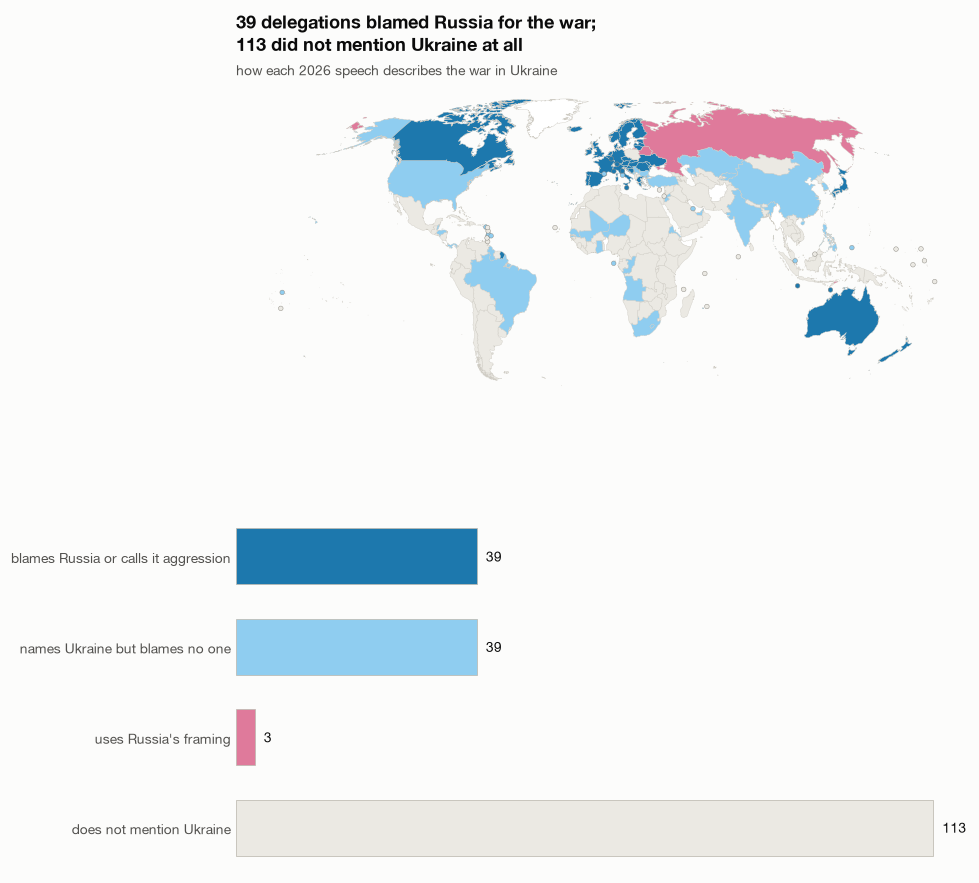

In [2]:
u26 = ukr[ukr.year == 2026]
counts = u26.cls.value_counts().reindex(list(UK), fill_value=0)

fig, (ax, bx) = plt.subplots(2, 1, figsize=SQUARE, gridspec_kw={"height_ratios": [1.7, 1]})
world_map(ax, {r.iso3: UK[r.cls] for r in u26.itertuples() if r.iso3 in STATES})
finalize(ax, f"{counts[BLAMES]} delegations blamed Russia for the war;\n{counts[SILENT]} did not mention Ukraine at all",
         "how each 2026 speech describes the war in Ukraine")
bx.barh(range(len(UK)), counts.values, color=list(UK.values()), edgecolor="#bdb9b0", linewidth=0.5, height=0.62)
for y, (label, n) in enumerate(counts.items()):
    bx.text(n + 1.5, y, f"{n}", va="center", fontsize=9, color=INK)
bx.set_yticks(range(len(UK)), list(UK), fontsize=9); bx.invert_yaxis(); bx.set_xticks([]); bx.tick_params(length=0)
for side in ("left", "bottom"):
    bx.spines[side].set_visible(False)
plt.tight_layout(); show(fig, "w1_ukraine_map")

**what they said.** the sentence behind each label, for a few countries in each framing.

In [3]:
for cls in [BLAMES, NO_BLAME, RUSSIAS]:
    group = u26[u26.cls == cls]
    print(f"{cls.upper()} ({len(group)})\n")
    say(group, n=4)

BLAMES RUSSIA OR CALLS IT AGGRESSION (39)

  “In Ukraine, for almost five years now, Russia has been waging a cruel war on civilians.”
     — Emmanuel Macron, President, France

  “I was in Kyiv last month, and it gave me a glimpse of life under Russian attack.”
     — Andy Burnham, Prime Minister, United Kingdom of Great Britain and Northern Ireland

  “Today, Germany is the largest supporter of Ukraine in its defence against Russian aggression.”
     — Johann Wadephul, Federal Minister for Foreign Affairs, Germany

  “Russia’s aggression against Ukraine is the most obvious example.”
     — Takaichi Sanae, Prime Minister, Japan

NAMES UKRAINE BUT BLAMES NO ONE (39)

  “We're working very closely with the leaders of Russia and Ukraine, and we will get that one done.”
     — Donald Trump, President, United States of America

  “On Ukraine, President XI Jinping has put forward four points on what must be done, which are the
   fundamental guidance for China in playing a continued constru

## 2. how has the wording changed since 2022, and who changed it?

each column is one debate. each block is the speeches with one framing, and the bands follow the same delegation from one debate to the next, coloured by where it came from.

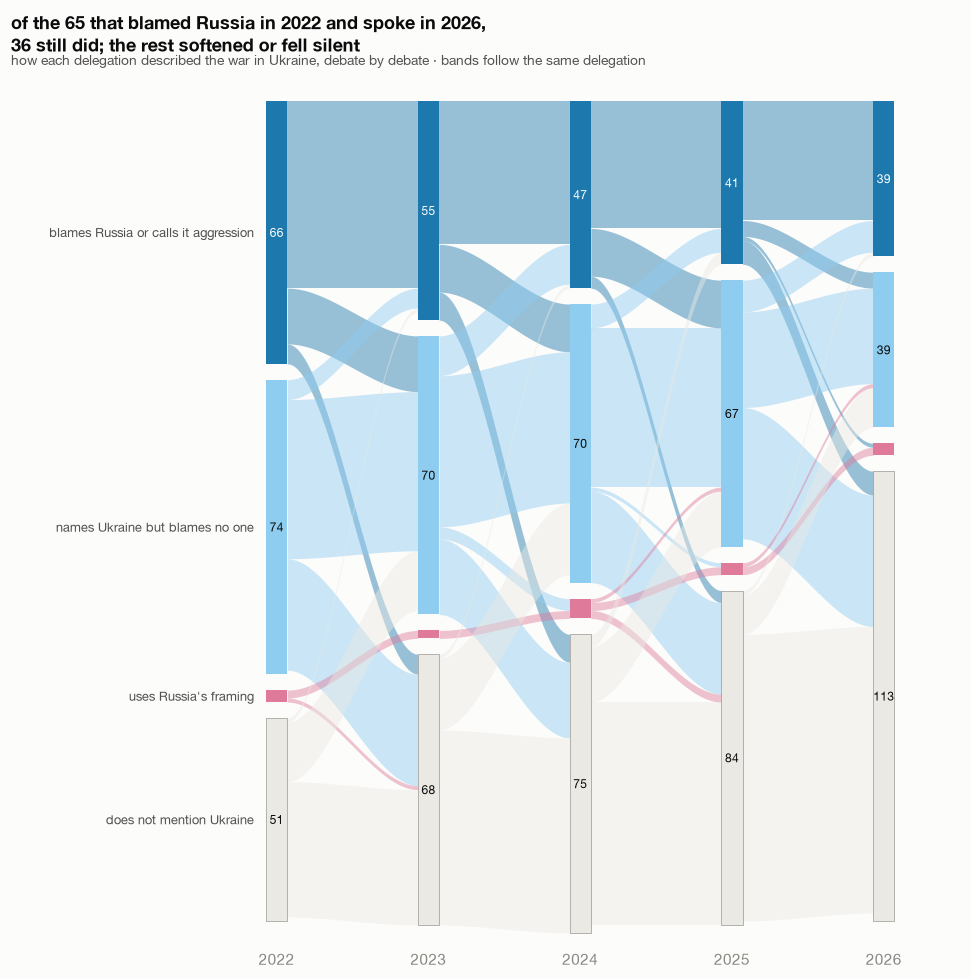

the 2022 blamers in 2026: {'blames Russia or calls it aggression': 36, 'names Ukraine but blames no one': 10, "uses Russia's framing": 1, 'does not mention Ukraine': 18} 

names Ukraine but blames no one in 2026 (10): Barbados, Belize, Bulgaria, Ghana, Montenegro, Palau, President of the
General Assembly (opening), Serbia, Singapore, United States of America 

does not mention Ukraine in 2026 (18): Albania, Botswana, Chile, Comoros, Cyprus, Djibouti, Dominica, Dominican
Republic, Ecuador, Fiji, Georgia, Grenada, Marshall Islands, Micronesia (Federated States of), North Macedonia, Poland,
Switzerland, Uruguay 



In [4]:
cls_in = {y: dict(zip(ukr[ukr.year == y].iso3, ukr[ukr.year == y].cls)) for y in YEARS}
ORDER, GAP_ROWS, WIDTH = list(UK), 4, 0.14


def blocks(year):
    """where each framing's block sits in a year's column: (top, height), stacked in a fixed order with a gap between."""
    n = pd.Series(cls_in[year]).value_counts().reindex(ORDER, fill_value=0)
    top, out = 0, {}
    for c in ORDER:
        out[c] = (top, n[c])
        top += n[c] + GAP_ROWS
    return out


def ribbon(ax, x0, x1, top0, top1, h, colour):
    """a band h countries thick from one column's block to the next, along a smooth s-curve."""
    t = np.linspace(0, 1, 40)
    e = 3 * t**2 - 2 * t**3
    x = x0 + (x1 - x0) * t
    ax.fill_between(x, top0 + (top1 - top0) * e, top0 + h + (top1 - top0) * e, color=colour, alpha=0.45, lw=0)


fig, ax = plt.subplots(figsize=SQUARE)
pos = {y: blocks(y) for y in YEARS}
for i, (a, b) in enumerate(zip(YEARS, YEARS[1:])):
    both = [iso for iso in cls_in[a] if iso in cls_in[b]]
    pairs = pd.Series([(cls_in[a][iso], cls_in[b][iso]) for iso in both]).value_counts()
    out_off = {c: pos[a][c][0] for c in ORDER}
    in_off = {c: pos[b][c][0] for c in ORDER}
    # bands leave each block in the order of the block they go to, and arrive in the order of the block they came from
    for src in ORDER:
        for dst in ORDER:
            n = pairs.get((src, dst), 0)
            if n:
                ribbon(ax, i + WIDTH / 2, i + 1 - WIDTH / 2, out_off[src], in_off[dst], n, UK[src])
                out_off[src] += n
                in_off[dst] += n
for i, y in enumerate(YEARS):
    for c in ORDER:
        top, h = pos[y][c]
        ax.add_patch(Rectangle((i - WIDTH / 2, top), WIDTH, h, facecolor=UK[c], edgecolor="#8d8a82" if c == SILENT else "none", lw=0.4))
        if h >= 6:
            ax.text(i, top + h / 2, str(h), ha="center", va="center", fontsize=8, color=SURFACE if c == BLAMES else INK)
for c in ORDER:
    top, h = pos[YEARS[0]][c]
    ax.text(-WIDTH / 2 - 0.08, top + h / 2, c, ha="right", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(-1.75, len(YEARS) - 0.5); ax.set_ylim(max(t + h for t, h in pos[YEARS[0]].values()) + 6, -4)
ax.set_xticks(range(len(YEARS)), YEARS); ax.set_yticks([]); ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)

blamed22 = [iso for iso, c in cls_in[2022].items() if c == BLAMES and iso in cls_in[2026]]
still = sum(cls_in[2026][iso] == BLAMES for iso in blamed22)
finalize(ax, f"of the {len(blamed22)} that blamed Russia in 2022 and spoke in 2026,\n{still} still did; the rest softened or fell silent",
         "how each delegation described the war in Ukraine, debate by debate · bands follow the same delegation")
plt.tight_layout(); show(fig, "w2_ukraine_flows")

# where the 2022 blamers went, and who they are
went = pd.Series({iso: cls_in[2026][iso] for iso in blamed22}).value_counts().reindex(ORDER, fill_value=0)
print("the 2022 blamers in 2026:", went[went > 0].to_dict(), "\n")
names = ukr.drop_duplicates("iso3").set_index("iso3").delegation
for c in [NO_BLAME, SILENT]:
    who = sorted(names[iso] for iso in blamed22 if cls_in[2026][iso] == c)
    print(textwrap.fill(f"{c} in 2026 ({len(who)}): " + ", ".join(who), 120), "\n")

one speech in the "does not mention Ukraine" group still condemns Russia: Poland's in 2026 speaks of Russia's "open aggression" and its "attacks on ports and ships transporting grain" without naming Ukraine. it is the only such case from 2022 to 2026.

## 3. how does each country describe Gaza?

each country is coloured by the strongest criticism of Israel in its speech. a black dot marks a speech that names Hamas, the hostages or 7 October. the 2023 debate came before 7 October, so the bars start in 2024. criticism that names no actor is often missed, so the pink shares are a floor (see how well the rules read, at the end); the genocide shares are reliable.

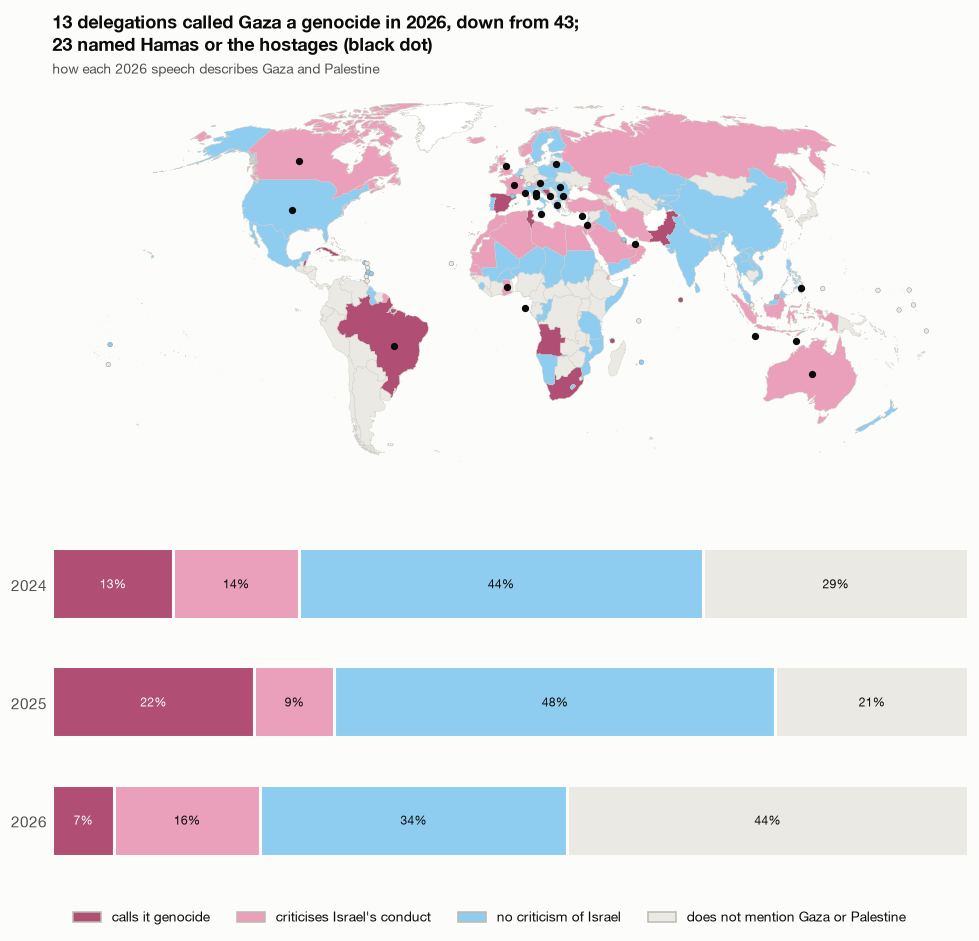

named Hamas or the hostages, by year: {2024: 58, 2025: 71, 2026: 23}


In [5]:
g = {y: gz[gz.year == y] for y in (2024, 2025, 2026)}
g26 = g[2026]
n26 = g26.cls.value_counts().reindex(list(GZ), fill_value=0)
n25 = g[2025].cls.value_counts().reindex(list(GZ), fill_value=0)

fig, (ax, bx) = plt.subplots(2, 1, figsize=SQUARE, gridspec_kw={"height_ratios": [1.7, 1]})
world_map(ax, {r.iso3: GZ[r.cls] for r in g26.itertuples() if r.iso3 in STATES})
shapes = world()
hamas = shapes[shapes.ISO_A3_EH.isin(set(g26[g26.hamas].iso3))].representative_point()
ax.scatter(hamas.x, hamas.y, s=14, color=INK, zorder=4)
finalize(ax, f"{n26[GENOCIDE]} delegations called Gaza a genocide in 2026, down from {n25[GENOCIDE]};\n"
             f"{int(g26.hamas.sum())} named Hamas or the hostages (black dot)",
         "how each 2026 speech describes Gaza and Palestine")

# the same framings in each debate since the war began, as shares of the speeches
share = pd.DataFrame({y: g[y].cls.value_counts(normalize=True).reindex(list(GZ), fill_value=0) for y in g}).T
left = np.zeros(len(share))
for c in GZ:
    bx.barh([str(y) for y in share.index], share[c], left=left, color=GZ[c], edgecolor=SURFACE, linewidth=2, height=0.6, label=c)
    for k, (l, v) in enumerate(zip(left, share[c])):
        if v >= 0.06:
            bx.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=8, color=SURFACE if c == GENOCIDE else INK)
    left += share[c].values
bx.invert_yaxis(); bx.set_xlim(0, 1); bx.set_xticks([]); bx.tick_params(length=0)
for side in ("left", "bottom"):
    bx.spines[side].set_visible(False)
legend(fig, [(c, GZ[c]) for c in GZ])
plt.tight_layout(rect=(0, 0.06, 1, 1)); show(fig, "w3_gaza_map")

print("named Hamas or the hostages, by year:", {y: int(g[y].hamas.sum()) for y in g})

In [6]:
for cls in [GENOCIDE, CONDUCT]:
    group = g26[g26.cls == cls]
    print(f"{cls.upper()} ({len(group)})\n")
    say(group, n=4)
print(f"NAMES HAMAS OR THE HOSTAGES ({int(g26.hamas.sum())})\n")
say(g26[g26.hamas], n=4, col="hamas_evidence")

CALLS IT GENOCIDE (13)

  “Generations of Palestinians will carry the pain and trauma left by the genocide of women and children
   perpetrated by the Netanyahu government in Gaza.”
     — Luiz Inácio Lula Da Silva, President, Brazil

  “The State of Israel’s continued violations of international and humanitarian law constitute genocide, and
   we remain steadfast in our view that the international community must act decisively to end this impunity.”
     — Ronald Ozzy Lamola, Minister for International Relations and Cooperation, South Africa

  “This is following long decades of historic injustice, uprooting asylum seeking occupation and the
   deprivation of its basic right to self-determination, freedom and independence in the Gaza Strip, our
   people are being subjected at the hands of the Israeli occupation forces to killing, destruction,
   starvation and attempts at displacement, as well as a genocidal war that has created an unprecedented
   humanitarian catastrophe.”
     — M

## 4. do the countries that condemn one war condemn the other?

each cell counts the 2026 speeches with one framing of Ukraine and one of Gaza. the two outlined cells are the mismatches critics call double standards: strong language for one war and none for the other. the table below tests, debate by debate, whether blaming Russia goes with criticising Israel.

**no consistent link.** in 2024 and 2025, blaming Russia made no clear difference to whether a country criticised Israel. in 2026 the countries that blamed Russia were more likely to criticise Israel (in the table below), but that is one test of three, and it does not pass the stricter bar for running three (p below 0.05 ÷ 3). the test is weak, with few countries in the strong cells, and in earlier years the rules miss up to 4 in 10 critical speeches. so the data show no settled pattern either way. the regions printed below show who sits in each group.

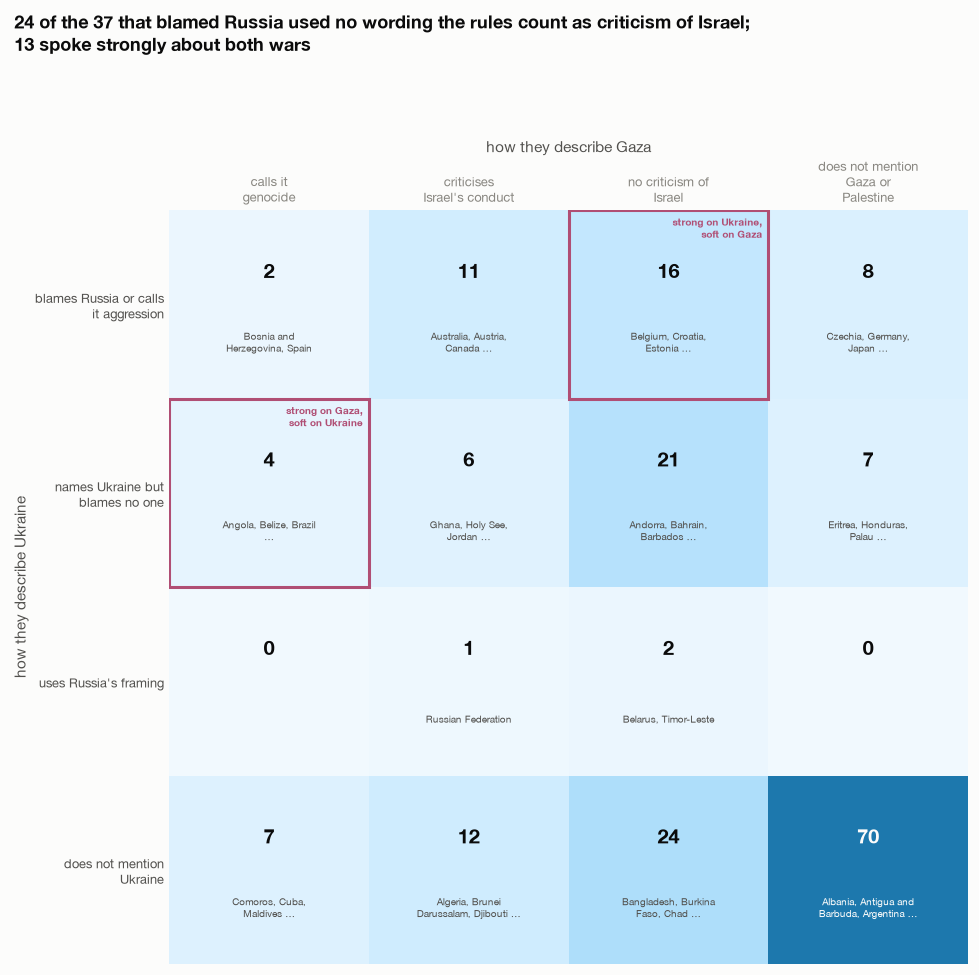

      blame Russia and criticise Israel  blame Russia only  criticise Israel only  neither  odds ratio  p (Fisher)
year                                                                                                              
2024                                  9                 37                     44      103        0.57        0.19
2025                                 12                 28                     47      104        0.95        1.00
2026                                 13                 24                     30      124        2.24        0.05 

blames Russia, by region: {'Europe': 33, 'Oceania': 2, 'Americas': 1, 'Asia': 1}
calls Gaza a genocide or criticises Israel, by region: {'Asia': 13, 'Europe': 13, 'Africa': 12, 'Americas': 4, 'Oceania': 1}


In [7]:
both = ukr[["year", "iso3", "delegation", "cls"]].merge(gz[["year", "iso3", "cls", "hamas"]], on=["year", "iso3"], suffixes=("_ukr", "_gaza"))
b26 = both[(both.year == 2026) & both.iso3.isin(STATES)]
rows, cols = list(UK), list(GZ)
grid = pd.crosstab(b26.cls_ukr, b26.cls_gaza).reindex(index=rows, columns=cols, fill_value=0)

fig, ax = plt.subplots(figsize=SQUARE)
ax.imshow(grid.values, cmap=RAMP, vmin=0, vmax=grid.values.max(), aspect="auto")
short = lambda n: n.split(" (")[0].replace("United Kingdom of Great Britain and Northern Ireland", "UK").replace("United States of America", "US")
for i, r in enumerate(rows):
    for j, c in enumerate(cols):
        who = sorted(short(n) for n in b26[(b26.cls_ukr == r) & (b26.cls_gaza == c)].delegation)
        n = grid.at[r, c]
        dark = n > grid.values.max() * 0.6
        ax.text(j, i - 0.18, str(n), ha="center", va="center", fontsize=13, fontweight="bold", color=SURFACE if dark else INK)
        if n:
            ax.text(j, i + 0.2, textwrap.fill(", ".join(who[:3]) + (" …" if n > 3 else ""), 22), ha="center", va="center", fontsize=6.5,
                    color=SURFACE if dark else INK_2)
for (i, j), label in {(0, 2): "strong on Ukraine,\nsoft on Gaza", (1, 0): "strong on Gaza,\nsoft on Ukraine"}.items():
    ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, edgecolor=ROSE_INK, lw=2))
    ax.text(j + .47, i - .47, label, ha="right", va="top", fontsize=6.5, color=ROSE_INK, fontweight="bold")
ax.set_yticks(range(len(rows)), [textwrap.fill(r, 22) for r in rows], fontsize=8.5)
ax.set_xticks(range(len(cols)), [textwrap.fill(c, 16) for c in cols], fontsize=8.5)
ax.xaxis.tick_top(); ax.tick_params(length=0)
ax.set_ylabel("how they describe Ukraine"); ax.set_xlabel("how they describe Gaza"); ax.xaxis.set_label_position("top")
for s in ax.spines.values():
    s.set_visible(False)
strong_ukr = grid.loc[BLAMES].sum()
soft_gaza = grid.at[BLAMES, NO_CRITICISM] + grid.at[BLAMES, NO_GAZA]
fig.suptitle(f"{soft_gaza} of the {strong_ukr} that blamed Russia used no wording the rules count as criticism of Israel;\n"
             f"{grid.loc[BLAMES, [GENOCIDE, CONDUCT]].sum()} spoke strongly about both wars",
             x=0.02, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.93)); show(fig, "w4_both_wars")

# is blaming russia linked to criticising israel? one 2x2 test per debate since the war in Gaza began
tests = []
for y in (2024, 2025, 2026):
    d = both[(both.year == y) & both.iso3.isin(STATES)]
    t = pd.crosstab(d.cls_ukr == BLAMES, d.cls_gaza.isin([GENOCIDE, CONDUCT])).reindex(index=[True, False], columns=[True, False], fill_value=0)
    odds, p = stats.fisher_exact(t.values)
    tests.append({"year": y, "blame Russia and criticise Israel": t.at[True, True], "blame Russia only": t.at[True, False],
                  "criticise Israel only": t.at[False, True], "neither": t.at[False, False], "odds ratio": odds, "p (Fisher)": p})
print(pd.DataFrame(tests).set_index("year").round({"odds ratio": 2, "p (Fisher)": 3}).to_string(), "\n")

# who sits where in 2026, by UN region
b26 = b26.assign(region=b26.iso3.map(REGION))
print("blames Russia, by region:", b26[b26.cls_ukr == BLAMES].region.value_counts().to_dict())
print("calls Gaza a genocide or criticises Israel, by region:", b26[b26.cls_gaza.isin([GENOCIDE, CONDUCT])].region.value_counts().to_dict())

**speakers who make the comparison themselves.**

In [8]:
# speakers who name the comparison themselves
pairing = texts[texts.year == 2026]
pairing = pairing.assign(evidence=pairing.english_text_clean.map(
    lambda t: next((s for s in wording._sentences(t) if wording.UKRAINE.search(s) and wording.GAZA.search(s) and len(s.split()) <= 70), "")))
pairing = pairing[pairing.evidence.ne("")]
print(f"sentences that name Ukraine and Gaza or Palestine together in 2026: {len(pairing)}\n")
say(pairing, n=6)

sentences that name Ukraine and Gaza or Palestine together in 2026: 18

  “From Gaza to Ukraine and Russia, from Myanmar to Darfur, from Iran to Lebanon, 250,000 people have lost
   their lives.”
     — Recep Tayyip Erdoğan, President, Türkiye

  “From what we have observed, we do not discern encouraging signs regarding the likelihood of reaching any
   peace agreement in the near future in the wars between Russia and Ukraine, in the Israeli-Palestinian
   conflict in the Middle East and in the Persian Gulf.”
     — João Manuel Gonçalves Lourenço, President, Angola

  “My friends, the scale of human tragedy is mounting, and whether it is in Gaza or the West Bank or Lebanon,
   or Yemen or Sudan or Ukraine or elsewhere.”
     — Mia Amor Mottley, Prime Minister, Barbados

  “The strengthening of authoritarian populism, the aggression against Ukraine, the suffering in Gaza, the war
   in the Gulf region, the catastrophic situation in Sudan and other flashpoints have brought humanity into 

## 5. do the words match the votes?

two General Assembly votes on Ukraine, each set against the speeches given that September: [ES-11/1](https://digitallibrary.un.org/record/3959039) in March 2022, and [ES-11/7](https://digitallibrary.un.org/record/4076672) in February 2025, when the United States voted against a resolution backed by Ukraine and Europe. the votes are in [`reference/ukraine_votes.csv`](https://github.com/jeremychia/unga-speeches/blob/main/reference/ukraine_votes.csv). the 2022 list matches the UN's voting record country by country; the 2025 list is transcribed from Wikipedia and matches the official totals (93 yes, 18 no, 65 abstaining, 17 absent).

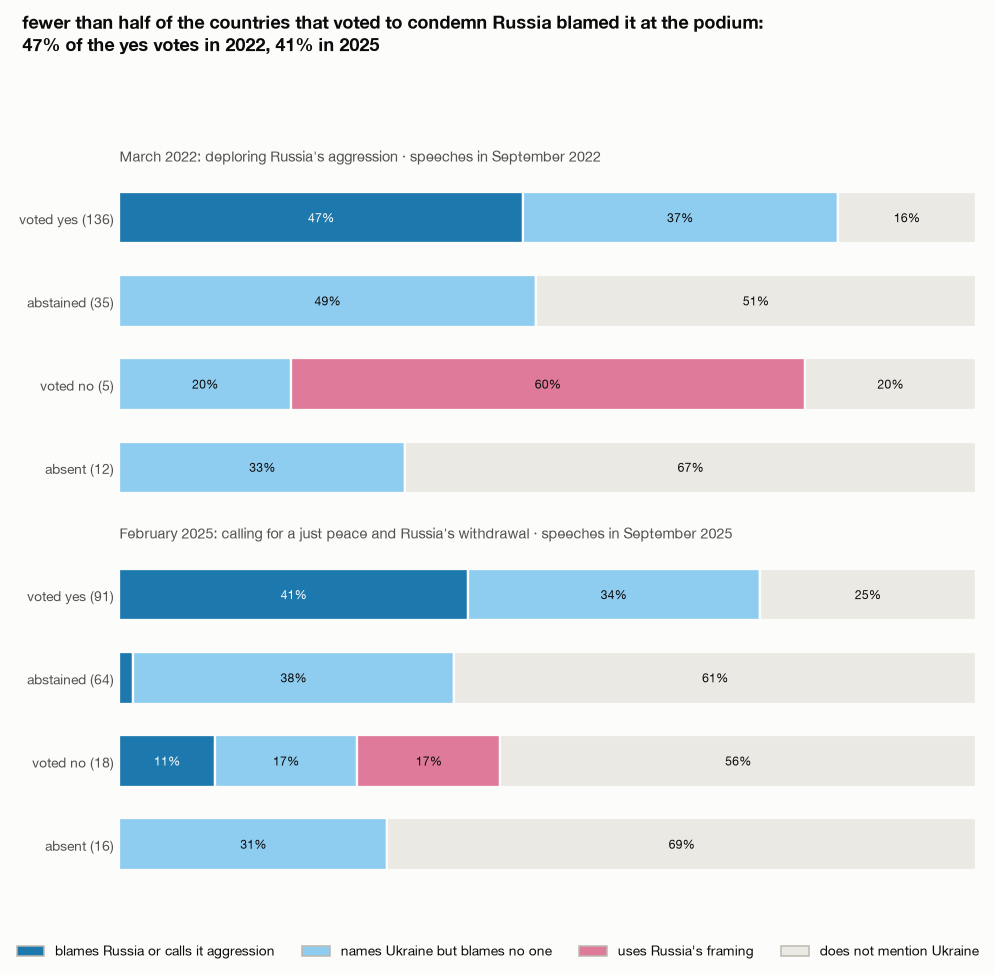

voted no in 2025 but blamed Russia that September: ['Marshall Islands', 'Palau'] 

2022: share of speeches blaming Russia, by vote: {'voted yes': '47% of 136', 'abstained': '0% of 35', 'voted no': '0% of 5', 'absent': '0% of 12'}
2025: share of speeches blaming Russia, by vote: {'voted yes': '41% of 91', 'abstained': '2% of 64', 'voted no': '11% of 18', 'absent': '0% of 16'}


In [9]:
VOTES = ["yes", "abstain", "no", "absent"]
VOTE_LABEL = {"yes": "voted yes", "abstain": "abstained", "no": "voted no", "absent": "absent"}
panels = [(2022, "ES-11/1", "March 2022: deploring Russia's aggression"), (2025, "ES-11/7", "February 2025: calling for a just peace and Russia's withdrawal")]

fig, axes = plt.subplots(2, 1, figsize=SQUARE)
summary = {}
for ax, (year, res, label) in zip(axes, panels):
    d = ukr[ukr.year == year].merge(votes[res].rename("vote"), left_on="iso3", right_index=True)
    share = pd.crosstab(d.vote, d.cls, normalize="index").reindex(index=VOTES, columns=list(UK), fill_value=0)
    n = d.vote.value_counts().reindex(VOTES, fill_value=0)
    summary[year] = (share, n)
    left = np.zeros(len(VOTES))
    for c in UK:
        ax.barh(range(len(VOTES)), share[c], left=left, color=UK[c], edgecolor=SURFACE, linewidth=1.5, height=0.62)
        for k, (l, v) in enumerate(zip(left, share[c])):
            if v >= 0.09:
                ax.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=8, color=SURFACE if c == BLAMES else INK)
        left += share[c].values
    ax.set_yticks(range(len(VOTES)), [f"{VOTE_LABEL[v]} ({n[v]})" for v in VOTES], fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xticks([]); ax.tick_params(length=0)
    for side in ("left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_title(f"{label} · speeches in September {year}", fontsize=9.5, fontweight="normal", color=INK_2)
yes22 = summary[2022][0].at["yes", BLAMES]
yes25 = summary[2025][0].at["yes", BLAMES]
fig.suptitle(f"fewer than half of the countries that voted to condemn Russia blamed it at the podium:\n"
             f"{yes22:.0%} of the yes votes in 2022, {yes25:.0%} in 2025", x=0.02, ha="left", fontweight="bold", fontsize=12)
legend(fig, [(c, UK[c]) for c in UK])
plt.tight_layout(rect=(0, 0.08, 1, 0.92)); show(fig, "w5_words_and_votes")

no25 = ukr[(ukr.year == 2025) & (ukr.cls == BLAMES)].merge(votes["ES-11/7"].rename("vote"), left_on="iso3", right_index=True)
print("voted no in 2025 but blamed Russia that September:", sorted(no25[no25.vote == "no"].delegation), "\n")
for year, (share, n) in summary.items():
    print(f"{year}: share of speeches blaming Russia, by vote:", {VOTE_LABEL[v]: f"{share.at[v, BLAMES]:.0%} of {n[v]}" for v in VOTES})

**who moved.** the countries that voted yes in 2022 and not in 2025, with the framing of their speech each year.

In [10]:
# the countries that voted yes in 2022 but not in 2025, with how they described the war in each year's speech
moved = votes[(votes["ES-11/1"] == "yes") & (votes["ES-11/7"] != "yes")].copy()
names = ref.dropna(subset=["iso3"]).drop_duplicates("iso3").set_index("iso3").name
for y in (2022, 2025, 2026):
    moved[f"speech {y}"] = moved.index.map(cls_in[y]).fillna("no speech on record")
moved.insert(0, "delegation", moved.index.map(names))
print(f"{len(moved)} countries voted yes in 2022 and did not in 2025:", moved["ES-11/7"].value_counts().to_dict())
moved.sort_values(["ES-11/7", "delegation"]).reset_index(drop=True)

48 countries voted yes in 2022 and did not in 2025: {'abstain': 35, 'no': 7, 'absent': 6}


resolution,delegation,ES-11/1,ES-11/7,speech 2022,speech 2025,speech 2026
0,Afghanistan,yes,absent,no speech on record,no speech on record,no speech on record
1,Benin,yes,absent,names Ukraine but blames no one,does not mention Ukraine,no speech on record
2,Democratic Republic of the Congo,yes,absent,names Ukraine but blames no one,names Ukraine but blames no one,does not mention Ukraine
3,Dominica,yes,absent,blames Russia or calls it aggression,does not mention Ukraine,does not mention Ukraine
4,Ecuador,yes,absent,blames Russia or calls it aggression,does not mention Ukraine,does not mention Ukraine
5,Georgia,yes,absent,blames Russia or calls it aggression,names Ukraine but blames no one,does not mention Ukraine
6,Argentina,yes,abstain,names Ukraine but blames no one,does not mention Ukraine,does not mention Ukraine
7,Bahrain,yes,abstain,does not mention Ukraine,does not mention Ukraine,names Ukraine but blames no one
8,Botswana,yes,abstain,blames Russia or calls it aggression,names Ukraine but blames no one,does not mention Ukraine
9,Brazil,yes,abstain,names Ukraine but blames no one,names Ukraine but blames no one,names Ukraine but blames no one


## caveats

- **rules, not readers.** the framings come from word patterns. they miss criticism in unusual words, and can mistake a quoted accusation or someone else's aggression for the speaker's own. the evidence sentence is kept so any label can be checked, and the blind check below measures how often they are wrong.
- **strongest framing only.** a speech that blames Russia and also calls for talks is counted as blaming Russia.
- **the texts change kind** between years, as noted at the top.
- **one sentence decides.** a single strong sentence is enough for a label, however long the rest of the speech.

## how well the rules read

each sample was labelled blind, from the extracted sentences alone, by a reader that never saw the rules (a separate AI model each time, not a person). the samples are listed in [`analysis/wording_check.py`](https://github.com/jeremychia/unga-speeches/blob/main/src/unga_speeches/analysis/wording_check.py), which also redraws them and rebuilds the passages the readers saw; the labels are in [`tests/fixtures/wording_blind_labels.csv`](https://github.com/jeremychia/unga-speeches/blob/main/tests/fixtures/wording_blind_labels.csv). the **review**, **holdout** and **full 2026** samples were each used to correct the rules after they were scored, so their scores now flatter the rules. the **final** sample was drawn after the last correction from speeches no reader had seen, and the rules were not changed after it was scored: it is the fair measure.

**what it shows.** on the final sample, the rules and the reader agree on 39 of 40 Ukraine speeches: every speech the rules say blames Russia does, and they catch 18 of the 19 that do. for Gaza they agree on 30 of 40. every speech the rules call critical of Israel is, but they catch only 12 of the 20 the reader found critical, mostly implicit criticism such as "collective punishment" or "the interruption of water, food and energy supplies" with no actor named. naming Hamas or the hostages agrees on all 40. so the Ukraine counts and the genocide counts can be read as they stand; the counts of criticism of Israel are a floor, too low by as much as 4 in 10 in 2024 and 2025. for 2026, where a reader labelled every speech, the rules now agree on 105 of 109.

In [11]:
from unga_speeches.analysis import wording_check

labels = pd.read_csv(ROOT / "tests/fixtures/wording_blind_labels.csv")
print(wording_check.score(labels, classified).to_string(index=False), "\n")
final = labels[labels["sample"] == "final"].merge(classified, on=["year", "iso3"], suffixes=("", "_rules"))
for war in ["ukraine", "gaza"]:
    d = final[final.war == war]
    print(f"final sample, {war}: rows are the blind label, columns the rules")
    print(pd.crosstab(d.label, d[war]).to_string(), "\n")
g = final[final.war == "gaza"]
print("final sample, names hamas or the hostages:", int((g.hamas.astype(bool) == g.hamas_rules.astype(bool)).sum()), "of", len(g), "agree")

   sample     war  speeches  agree strong, rules right strong, rules caught
   review ukraine        40     39            22 of 22             22 of 23
   review    gaza        40     37            17 of 19             17 of 18
  holdout ukraine        30     26              8 of 9              8 of 11
  holdout    gaza        30     26            14 of 14             14 of 17
full 2026 ukraine        81     81            39 of 39             39 of 39
full 2026    gaza       109    105            44 of 44             44 of 47
    final ukraine        40     39            18 of 18             18 of 19
    final    gaza        40     30            12 of 12             12 of 20 

final sample, ukraine: rows are the blind label, columns the rules
ukraine                               blames Russia or calls it aggression  names Ukraine but blames no one  uses Russia's framing
label                                                                                                               